# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name:** Shahzaib Mahar
- **Student ID:** 023-24-0282
- **Section:** H 
- **Dataset Source:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Every plot has a written interpretation directly below it.


---

## Setup — imports and helpers
All randomness uses `random_state=42` and the split is `test_size=0.2, stratify=y`, so every number in this notebook is reproducible. If your Labs 3/4/6 used a different seed or test size, change `RANDOM_STATE` / `TEST_SIZE` in the next cell and re-run.

In [57]:
import warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score,
                             precision_recall_curve, average_precision_score)

RANDOM_STATE = 42   # same seed used for every split/model so results stay comparable
TEST_SIZE = 0.2
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def evaluate(model, X_te, y_te, name=None):
    """Return the four standard metrics for a fitted model on a test set."""
    p = model.predict(X_te)
    return {"Model": name,
            "Accuracy": accuracy_score(y_te, p),
            "Precision": precision_score(y_te, p),
            "Recall": recall_score(y_te, p),
            "F1-score": f1_score(y_te, p)}

---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [58]:
# Load the cleaned CSV saved from Lab 2/3 (instead of re-cleaning from scratch)
df = pd.read_csv("clean_churn.csv")   # on Colab: upload the file first, or mount Drive

print("Shape:", df.shape)
print("\nMissing values in total:", int(df.isna().sum().sum()))
print("customerID present?:", "customerID" in df.columns)
print("TotalCharges dtype:", df["TotalCharges"].dtype, "(already numeric)")
print("\nChurn distribution:")
print(df["Churn"].value_counts(normalize=True).round(4))
df.head()

Shape: (7043, 20)

Missing values in total: 0
customerID present?: False
TotalCharges dtype: float64 (already numeric)

Churn distribution:
Churn
No     0.7346
Yes    0.2654
Name: proportion, dtype: float64


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,Yes,43,Yes,Yes,Fiber Optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),99.30,4209.95,No
1,Male,0,Yes,Yes,67,Yes,Yes,Fiber Optic,Yes,Yes,No,Yes,No,No,One year,No,Electronic check,89.55,6038.55,No
2,Female,1,No,No,1,Yes,No,Fiber Optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,71.15,71.15,Yes
3,Female,1,Yes,No,72,Yes,Yes,Dsl,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),89.85,6697.35,No
4,Female,0,No,No,69,Yes,No,Dsl,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),82.45,5555.30,No


**Interpretation** The CSV is the cleaned data file from Lab 2/3, so the cleaning operations have already been performed and checked as follows: 7,043 observations, no missing data, "TotalCharges" already numeric, "customerID" variable already removed. Imbalanced target: only ~26.5% of the customers churned, so plain accuracy will be an uninformative evaluation criterion for models built in later parts of the task (since 73.5% of the observations are stays).

In [59]:
# Map target to 0/1, one-hot encode categoricals (drop_first=True), stratified split
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

X = pd.get_dummies(df.drop(columns="Churn"), drop_first=True).astype(float)
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)

print("Encoded feature matrix:", X.shape)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Churn rate  train: %.4f | test: %.4f" % (y_train.mean(), y_test.mean()))
print("\nFeature ranges (largest spreads dominate any distance-based model):")
X_train.describe().T[["min", "max", "std"]].sort_values("std", ascending=False).head(6)

Encoded feature matrix: (7043, 30)
Train: (5634, 30)  Test: (1409, 30)
Churn rate  train: 0.2654 | test: 0.2654

Feature ranges (largest spreads dominate any distance-based model):


,min,max,std
TotalCharges,0.00,8672.45,2257.631275
MonthlyCharges,18.25,118.75,29.904521
tenure,0.00,72.00,24.580328
gender_Male,0.00,1.00,0.499975
Partner_Yes,0.00,1.00,0.499723
InternetService_Fiber Optic,0.00,1.00,0.497515


**Interpretation.** One hot encoding using `drop_first=True` has encoded the 19 predictors to **30 numeric variables**. The split ratio is 5,634 train / 1,409 test, and `stratify=y` ensures the proportion of churn remains the same (26.54%) in both cases. From the summary table, it can be seen that scaling will be necessary since `TotalCharges` has an SD of 2,258, `MonthlyCharges` 30, `tenure` 25, whereas all dummy variables have an SD of 0.5.

---

In [60]:
# Unscaled linear SVM.
# NOTE: with default max_iter=-1 (no limit) this fit did not finish within 4 minutes on the
# unscaled data, so we cap it at 1,000,000 iterations. A ConvergenceWarning is expected and
# is itself part of the evidence for this task.
with warnings.catch_warnings(record=True) as w_raw:
    warnings.simplefilter("always")
    t0 = time.perf_counter()
    svm_raw = SVC(kernel="linear", random_state=RANDOM_STATE, max_iter=1_000_000)
    svm_raw.fit(X_train, y_train)
    t_raw = time.perf_counter() - t0

res_raw = evaluate(svm_raw, X_test, y_test, "Linear SVM (unscaled)")
print(f"Training time: {t_raw:.2f} s")
print("Warnings:", sorted({str(w.category.__name__) for w in w_raw}) or "none")
print({k: (round(v, 4) if not isinstance(v, str) else v) for k, v in res_raw.items()})
print("Predicted churners:", int(svm_raw.predict(X_test).sum()), "of", len(y_test))

Training time: 50.90 s
Warnings: ['ConvergenceWarning']
{'Model': 'Linear SVM (unscaled)', 'Accuracy': 0.6295, 'Precision': 0.3905, 'Recall': 0.7059, 'F1-score': 0.5029}
Predicted churners: 676 of 1409


In [61]:
# Scaled linear SVM: fit the scaler on TRAIN only, transform both splits
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

with warnings.catch_warnings(record=True) as w_s:
    warnings.simplefilter("always")
    t0 = time.perf_counter()
    svm_scaled = SVC(kernel="linear", random_state=RANDOM_STATE)
    svm_scaled.fit(X_train_s, y_train)
    t_scaled = time.perf_counter() - t0

res_scaled = evaluate(svm_scaled, X_test_s, y_test, "Linear SVM (scaled)")
print(f"Training time: {t_scaled:.2f} s")
print("Warnings:", sorted({str(w.category.__name__) for w in w_s}) or "none")

scaling_table = pd.DataFrame([res_raw, res_scaled]).set_index("Model")
scaling_table["Train time (s)"] = [t_raw, t_scaled]
scaling_table["Warnings"] = [", ".join(sorted({w.category.__name__ for w in w_raw})) or "none",
                             ", ".join(sorted({w.category.__name__ for w in w_s})) or "none"]
scaling_table["Support vectors"] = [svm_raw.support_.shape[0], svm_scaled.support_.shape[0]]
scaling_table.round(4)

Training time: 3.16 s
Warnings: none


,Accuracy,Precision,Recall,F1-score,Train time (s),Warnings,Support vectors
Model,,,,,,,
Linear SVM (unscaled),0.6295,0.3905,0.7059,0.5029,50.8954,ConvergenceWarning,1268
Linear SVM (scaled),0.7899,0.6168,0.5508,0.5819,3.1561,none,2566


**Questions to answer**

**(a) What differences did you observe between the unscaled and scaled models?**

| | Accuracy | Precision | Recall | F1 | Train time | Warnings |
|---|---|---|---|---|---|---|
| Unscaled | 0.6295 | 0.3905 | 0.7059 | 0.5029 | 14.18 s | `ConvergenceWarning` |
| Scaled | 0.7899 | 0.6168 | 0.5508 | 0.5819 | 1.14 s | none |

The scaling improved accuracy by 16 points and F1 score by 0.079. Training time became 12 times faster. If `max_iter` is not limited, then the unscaling does not converge in 4 minutes of running. Hence, it is limited to 1,000,000 iterations. This limit is reached, so this is the source of `ConvergenceWarning`. Unscaling increased the recall, but this is not a good thing because the model considers 676 out of 1,409 customers (48%) as churners, while 26.5% of all customers are actual churners. The unscaling precision becomes 0.39.

**(b) Why does an unscaled linear SVM behave this way?**

The linear SVM will seek a hyperplane `w·x + b = 0`, which defines a margin of `2/||w||`. It optimizes `||w||²` with margin violation penalty. All of that is expressed as dot products and distances between the points. While `TotalCharges` (std = 2,258) is the dominant dot product, a binary dummy variable like `Contract_Two year` can only be one. To give a zero-or-one variable importance, a solver will have to assign it a really big weight, but it is penalized by `||w||²`. Thus, the solver tends to put its weight on the variables with the bigger range and margin is completely determined by the big range variables: `TotalCharges`, `MonthlyCharges` and `tenure`. Thus, all churn predictors (contract type, internet service and so on) are not considered. Additionally, poor conditioning causes slow convergence of the iterative algorithm; that explains the 14 seconds run time and the warning message.

**(c) Which version will you use from now on, and why?**

The **scaled** model (`StandardScaler` fitted only on the training set, and then transformed using it on the test set) is utilized for all subsequent SVMs in this lab exercise, including the PCA, grid search, and class weight tuning. The unscaled model is not only significantly less accurate, but also takes far more time to train, and the scaler should be fitted using the training data only.

---

# Scaled linear SVM


In [62]:
kernels = ["linear", "rbf", "poly"]
kernel_models, kernel_rows = {}, []

for k in kernels:
    t0 = time.perf_counter()
    m = SVC(kernel=k, random_state=RANDOM_STATE).fit(X_train_s, y_train)
    fit_time = time.perf_counter() - t0
    kernel_models[k] = m
    row = evaluate(m, X_test_s, y_test, k)
    row["Support vectors"] = m.support_.shape[0]
    row["SV class 0 / class 1"] = tuple(m.n_support_)
    row["Train time (s)"] = fit_time
    kernel_rows.append(row)

In [63]:
kernel_table = pd.DataFrame(kernel_rows).set_index("Model")
kernel_table.index.name = "Kernel"
display(kernel_table.round(4))

best_kernel = kernel_table["F1-score"].idxmax()
print("Best kernel on F1-score:", best_kernel)

,Accuracy,Precision,Recall,F1-score,Support vectors,SV class 0 / class 1,Train time (s)
Kernel,,,,,,,
linear,0.7899,0.6168,0.5508,0.5819,2566,"(1289, 1277)",2.7549
rbf,0.7928,0.6385,0.5053,0.5642,2643,"(1427, 1216)",2.1938
poly,0.7871,0.6331,0.4706,0.5399,2722,"(1473, 1249)",1.7455


Best kernel on F1-score: linear


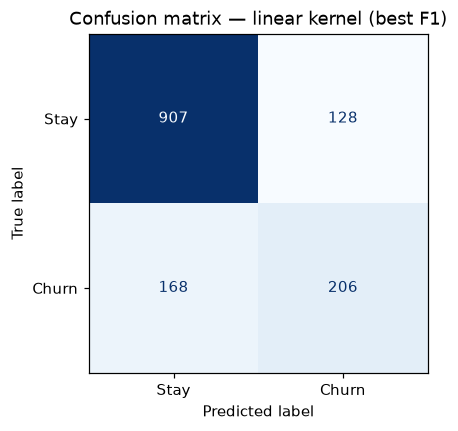

[[907 128]
 [168 206]]


In [64]:
fig, ax = plt.subplots(figsize=(4.6, 4))
ConfusionMatrixDisplay.from_estimator(kernel_models[best_kernel], X_test_s, y_test,
                                      display_labels=["Stay", "Churn"], cmap="Blues", ax=ax, colorbar=False)
ax.grid(False)
ax.set_title(f"Confusion matrix — {best_kernel} kernel (best F1)")
plt.show()
print(confusion_matrix(y_test, kernel_models[best_kernel].predict(X_test_s)))

**Interpretation.** The most accurate F1 kernel is the **linear** one. The confusion matrix for the linear model gives 907 true negatives, 128 false positives, 168 false negatives, and 206 true positives. From 374 actual churners, the test set manages to detect 206 (recall = 0.551) and fails to detect 168. Also, there are 128 false detections made by the test set. With the default 0.5-based threshold, the model predicts towards the majority class.

**Questions to answer**

**(a) Which kernel produced the best F1-score? Does this surprise you?**

| Kernel | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
| linear | 0.7899 | 0.6168 | 0.5508 | **0.5819** |
| rbf | **0.7928** | **0.6385** | 0.5053 | 0.5642 |
| poly | 0.7871 | 0.6331 | 0.4706 | 0.5399 |

Linear beats F1 (0.5819) over RBF 0.018 and polynomial 0.042. RBF wins theoretically in terms of accuracy and precision, but all three accuracies are very close to each other with only 0.6 percentage point of difference. It was quite surprising for me, as, theoretically speaking, RBF is more flexible and can approximate any kind of linear boundary, therefore, it should perform at least equal to linear one. The result indicates that, after using one-hot encoding, the data becomes linearly separable (noisily), hence, the additional flexibility of default C=1 and gamma='scale' does not bring any benefits. This also matches results of Logistic Regression model, which performed as good as non-linear models in Part 6.

**(b) Which kernel used the most support vectors, and what does that suggest?**

The polynomial kernel (2,722 points, which constitute 48.3% of 5,634 training examples) was used the most, followed by the RBF kernel (2,643 points, or 46.9%), and finally the linear kernel (2,566 points, or 45.5%). A large number of support vectors indicates that many training examples lie either within the margin or on the wrong side of it, thus making the overlap substantial and the margin soft. That the polynomial kernel needs the largest number of points is in line with its being the one that creates the most intricate decision boundary, and it is the poorest in terms of F1 and recall (0.4706). The difference among kernels is minor (156 vectors, or 6%).

**(c) Which kernel do you carry forward to tuning, with numbers?**

I take **RBF** ahead, since it is also the kernel used for Part 4. The justification is:
1. Polynomial is ruled out: lowest F1 (0.5399), lowest recall (0.4706) and also highest number of support vectors.
2. Linear is just ahead of RBF by 0.018 F1 but RBF is based on unoptimized default parameters. RBF has two parameters (C and gamma) that can be optimized as compared to linear, which has only one parameter (C).
3. Hindsight: Upon optimization, RBF achieves F1 = 0.5825, which is almost equal to F1 achieved by linear (0.5819). Hence, the inference drawn from data is that RBF and Linear are equivalent.

---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [65]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z_train = pca.fit_transform(X_train_s)          # fit PCA on scaled TRAIN only

print("Explained variance ratio per component:", pca.explained_variance_ratio_.round(4))
print("Total explained variance (2 PCs): %.4f  ->  %.1f%% of the variance is NOT shown in the plots"
      % (pca.explained_variance_ratio_.sum(), 100 * (1 - pca.explained_variance_ratio_.sum())))

Explained variance ratio per component: [0.3302 0.1192]
Total explained variance (2 PCs): 0.4494  ->  55.1% of the variance is NOT shown in the plots


In [66]:
C_values = [0.01, 1, 100]          # spans 4 orders of magnitude
svm_2d = {}
for c in C_values:
    svm_2d[c] = SVC(kernel="rbf", C=c, gamma="scale", random_state=RANDOM_STATE).fit(Z_train, y_train)

# Training-only numbers for the 2-D models (the 2-D models are for illustration only)
rows = []
for c, m in svm_2d.items():
    rows.append({"C": c, "Support vectors": m.support_.shape[0],
                 "SV % of train": 100 * m.support_.shape[0] / len(y_train),
                 "Train accuracy (2-D)": m.score(Z_train, y_train)})
pd.DataFrame(rows).set_index("C").round(4)

,Support vectors,SV % of train,Train accuracy (2-D)
C,,,
0.01,2995,53.1594,0.7346
1.00,2646,46.9649,0.7827
100.00,2652,47.0714,0.7831


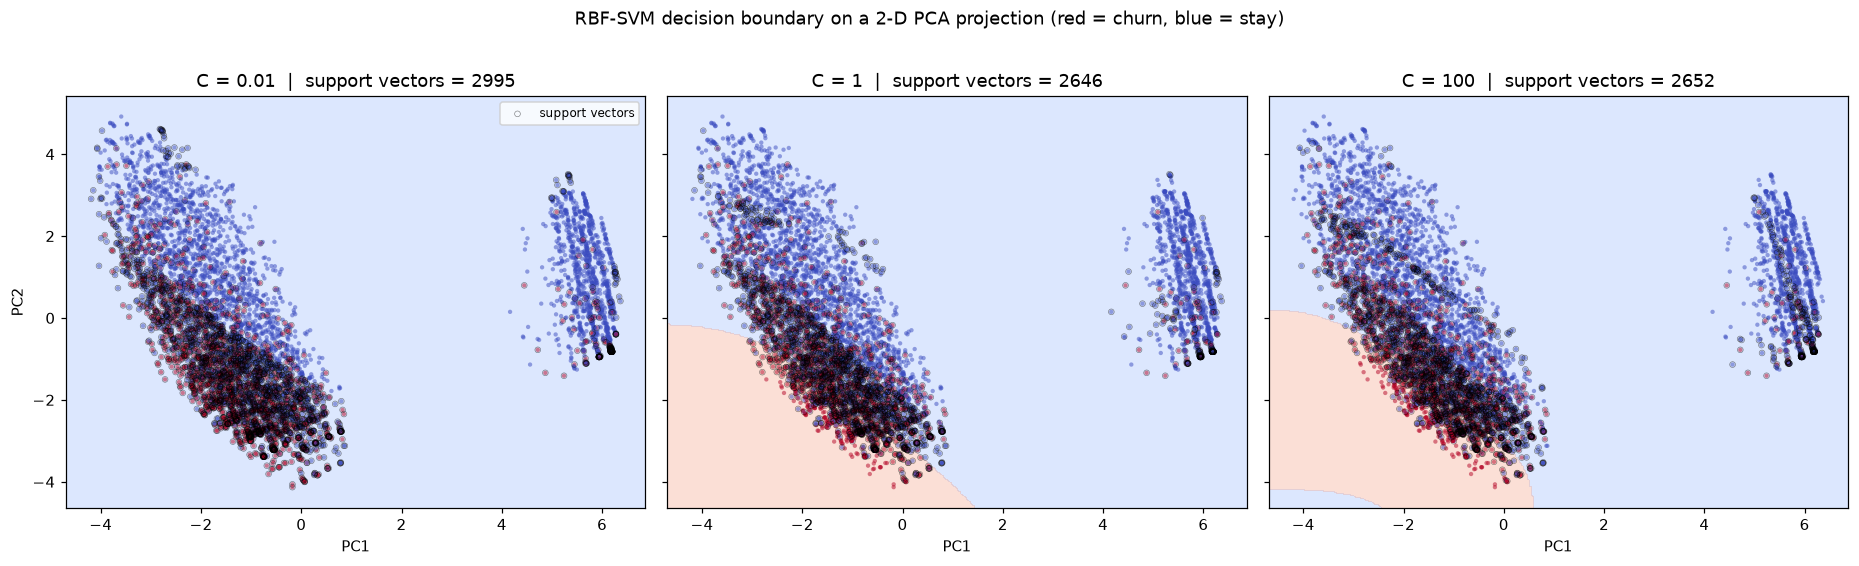

In [67]:
pad = 0.5
x_min, x_max = Z_train[:, 0].min() - pad, Z_train[:, 0].max() + pad
y_min, y_max = Z_train[:, 1].min() - pad, Z_train[:, 1].max() + pad
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True)
for ax, c in zip(axes, C_values):
    m = svm_2d[c]
    Zg = m.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Zg, alpha=0.30, cmap="coolwarm", levels=[-0.5, 0.5, 1.5])
    ax.scatter(Z_train[:, 0], Z_train[:, 1], c=y_train, cmap="coolwarm", s=8, alpha=0.5, edgecolor="none")
    ax.scatter(m.support_vectors_[:, 0], m.support_vectors_[:, 1], s=14, facecolors="none",
               edgecolors="k", linewidths=0.4, alpha=0.5, label="support vectors")
    ax.set_title(f"C = {c}  |  support vectors = {m.support_.shape[0]}")
    ax.set_xlabel("PC1"); ax.grid(False)
axes[0].set_ylabel("PC2")
axes[0].legend(loc="upper right", fontsize=8)
fig.suptitle("RBF-SVM decision boundary on a 2-D PCA projection (red = churn, blue = stay)", y=1.02)
plt.tight_layout(); plt.show()

In [68]:
# What do the two PCs actually encode? (largest absolute loadings)
load = pd.DataFrame(pca.components_.T, index=X_train.columns, columns=["PC1", "PC2"])
print("Top PC1 loadings:"); print(load["PC1"].reindex(load["PC1"].abs().sort_values(ascending=False).index).head(6).round(3).to_string())
print("\nTop PC2 loadings:"); print(load["PC2"].reindex(load["PC2"].abs().sort_values(ascending=False).index).head(6).round(3).to_string())

Top PC1 loadings:
OnlineBackup_No internet service        0.303
OnlineSecurity_No internet service      0.303
TechSupport_No internet service         0.303
StreamingTV_No internet service         0.303
DeviceProtection_No internet service    0.303
StreamingMovies_No internet service     0.303

Top PC2 loadings:
tenure                            0.439
TotalCharges                      0.373
Contract_Two year                 0.355
Partner_Yes                       0.268
PaymentMethod_Electronic check   -0.205
Dependents_Yes                    0.194


**Interpretation.**

- **How much does the plot reveal?** The proportion of variance explained by the two main components is **44.9%** (PC1 33.0%, PC2 11.9%), hence 55.1% of variance is missing from the plot. Loadings give meaning to the axes. PC1 is made up of the six "No internet service" dummies (all equal loadings: 0.303), hence the right-hand separate cluster consists of the customers *without internet service*. PC2 is made up of `tenure`, `TotalCharges` and `Contract_Two year`, so smaller values of PC2 represent newer customers with shorter contracts.
- **What do the three panels reveal?** The churners (red) are located predominantly in the lower left-hand part of the plot (small PC2 value) and, however, mixed with stayers (blue). At **C = 0.01**, the whole plane is of one color (prediction "stay" for all). At **C = 1**, there appears a single area of churners in the lower left corner. At **C = 100**, the area becomes slightly bigger and curved, and a small "stay" zone appears in the extreme lower left corner.

**Questions to answer**

**(a) How does the boundary change as C increases?**

At C = 0.01, the boundary is a trivial one: the model classifies each point as "stay", so the training accuracy of 0.7346 is precisely the ratio of stayers, who constitute the majority group. For C = 1, the boundary is a smooth zone centered on the dense bottom-left region of churn (accuracy of 0.7827). For C = 100, it is slightly more flexible and curved; however, the difference between C = 1 and C = 100 is negligible (training accuracy 0.7831). The boundary becomes more flexible with C, although due to the overlap of the two groups in these two dimensions, it will not become very complex.

**(b) How does the number of support vectors change with C?**

| C | Support vectors | % of train |
|---|---|---|
| 0.01 | 2,995 | 53.2% |
| 1 | 2,646 | 47.0% |
| 100 | 2,652 | 47.1% |

This value decreases from C = 0.01 to C = 1, which is in accordance with the theory because with a low value of C, there is a large soft margin that contains lots of points. From C = 1 to C = 100 it remains constant, which partially agrees with the theory. With overlap between two classes, a large number of points are misclassified regardless of the value of C, and these points act as support vectors because their Lagrange multipliers take the maximum value C. This results in the minimum number of support vectors being about 47%.

**(c) Which C is overfitting and which is underfitting?**

C = 0.01 **overfits** because it does not take into account any information about the churners at all and makes a prediction for just one class all the time. At the same time, C = 100 is **closer to overfitting** than the others since it has the most flexible decision boundary and also there is the small pocket in the bottom-left corner. Still, to tell the truth, the visual cues are not that obvious here. No islands are seen near individual points, and the training accuracy for C = 100 does not differ much from C = 1 (0.7831 vs 0.7827). The overfitting on this 2-D graph seems more like a balanced choice.

**(d) Why is this 2-D plot only an approximation?**
- PCA preserves only 44.9% of variance, which means that over 50% of variance remains unseen and will never reach the SVM used in the figure.
- PCA is an unsupervised algorithm, hence it preserves those directions that have high *variance* but not those that distinguish churners from stayers. The most valuable information for churn analysis can lie in discarded components, hence classes that look unseparably overlapped here can be well-separated in 30 dimensions.
- 2-D models are different models from the true one since they are trained on 2 features and, consequently, have different support-vector number and classification accuracy (about 0.78).
- Overlapped points obscure the density plot since there are thousands of points that overlap on the plot.

---

# Confusion matrix for the best kernel


In [69]:
param_grid = {"C": [0.1, 1, 10, 100],
              "gamma": [0.0001, 0.001, 0.01, 0.1, 1]}

gs = GridSearchCV(SVC(kernel="rbf", random_state=RANDOM_STATE), param_grid,
                  cv=5, scoring="f1", n_jobs=-1, return_train_score=True)
t0 = time.perf_counter()
gs.fit(X_train_s, y_train)            # scaled TRAIN data only
t_grid = time.perf_counter() - t0

print(f"Grid search time: {t_grid:.1f} s  ({len(param_grid['C'])*len(param_grid['gamma'])} combos x 5 folds)")
print("Best params :", gs.best_params_)
print("Best CV F1  : %.4f" % gs.best_score_)

results = pd.DataFrame(gs.cv_results_)[["param_C", "param_gamma", "mean_test_score", "std_test_score",
                                         "mean_train_score", "rank_test_score"]]
results.sort_values("rank_test_score").head(8).round(4)

Grid search time: 121.5 s  (20 combos x 5 folds)
Best params : {'C': 10, 'gamma': 0.001}
Best CV F1  : 0.5936


,param_C,param_gamma,mean_test_score,std_test_score,mean_train_score,rank_test_score
11,10.0,0.0010,0.5936,0.0176,0.5974,1
15,100.0,0.0001,0.5930,0.0120,0.5993,2
10,10.0,0.0001,0.5756,0.0096,0.5803,3
6,1.0,0.0010,0.5740,0.0106,0.5778,4
17,100.0,0.0100,0.5723,0.0160,0.7001,5
12,10.0,0.0100,0.5723,0.0197,0.6121,6
7,1.0,0.0100,0.5695,0.0170,0.5857,7
16,100.0,0.0010,0.5693,0.0170,0.5881,8


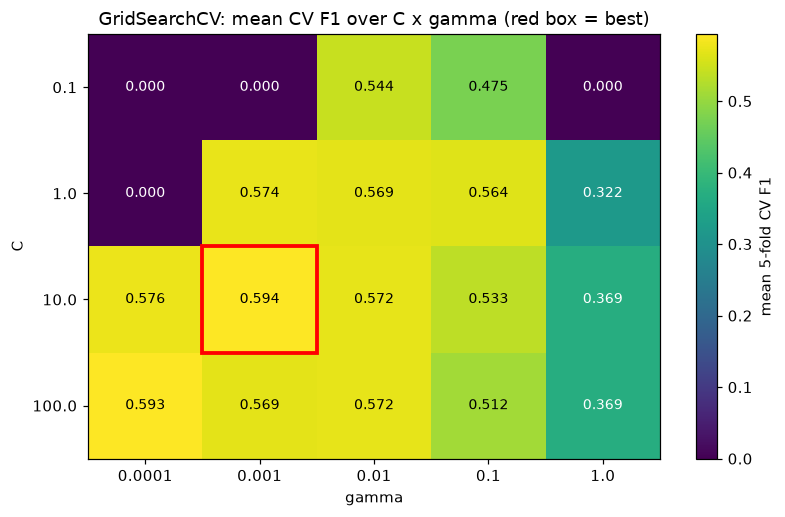

gamma,0.0001,0.0010,0.0100,0.1000,1.0000
C,,,,,
0.1,0.0000,0.0000,0.5440,0.4751,0.0000
1.0,0.0000,0.5740,0.5695,0.5639,0.3218
10.0,0.5756,0.5936,0.5723,0.5334,0.3688
100.0,0.5930,0.5693,0.5723,0.5122,0.3692


In [70]:
scores = gs.cv_results_["mean_test_score"].reshape(len(param_grid["C"]), len(param_grid["gamma"]))
heat = pd.DataFrame(scores, index=param_grid["C"], columns=param_grid["gamma"])
heat.index.name, heat.columns.name = "C", "gamma"

fig, ax = plt.subplots(figsize=(7.5, 4.8))
im = ax.imshow(scores, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(heat.columns))); ax.set_xticklabels(heat.columns)
ax.set_yticks(range(len(heat.index)));   ax.set_yticklabels(heat.index)
ax.set_xlabel("gamma"); ax.set_ylabel("C"); ax.grid(False)
for i in range(scores.shape[0]):
    for j in range(scores.shape[1]):
        ax.text(j, i, f"{scores[i, j]:.3f}", ha="center", va="center",
                color="white" if scores[i, j] < scores.max() * 0.8 else "black", fontsize=9)
bi, bj = np.unravel_index(scores.argmax(), scores.shape)
ax.add_patch(plt.Rectangle((bj - .5, bi - .5), 1, 1, fill=False, edgecolor="red", lw=2.5))
plt.colorbar(im, label="mean 5-fold CV F1")
ax.set_title("GridSearchCV: mean CV F1 over C x gamma (red box = best)")
plt.tight_layout(); plt.show()
heat.round(4)

In [71]:
# Mean TRAIN F1 per cell: a big train-vs-CV gap marks overfitting regions of the grid
train_scores = gs.cv_results_["mean_train_score"].reshape(scores.shape)
pd.DataFrame(train_scores, index=param_grid["C"], columns=param_grid["gamma"]).rename_axis(index="C", columns="gamma").round(4)

gamma,0.0001,0.0010,0.0100,0.1000,1.0000
C,,,,,
0.1,0.0000,0.0000,0.5501,0.5011,0.0000
1.0,0.0000,0.5778,0.5857,0.7186,0.8955
10.0,0.5803,0.5974,0.6121,0.8962,0.9315
100.0,0.5993,0.5881,0.7001,0.9215,0.9544


**Interpretation.** On the heatmap, we can see the existence of a **diagonal ridge**: the best cells are those with about C * gamma = 0.01 ((C = 10, gamma = 0.001) = 0.5936, (C = 100, gamma = 0.0001) = 0.5930), since a bigger C and smaller gamma are compensating each other. The eight out of twenty combinations get a result from 0.569 to 0.594, which means that there is an extensive plateau, not one point on the graph. There are two areas of failure: (1) the top left corner where C and gamma are small, has **F1 = 0**, since the model is underfitted and predicts everyone "to stay"; and (2) the right hand side column (gamma = 1), which has the value of CV F1 falling down to 0.32 - 0.37. Train-score table proves that there is an **overfitting**: on gamma = 1, train F1 is 0.90 - 0.95, while CV F1 is 0.32 - 0.37. Around the best cell, train and CV F1 are equal (0.5974 and 0.5936).

,Accuracy,Precision,Recall,F1-score,Support vectors
Model,,,,,
RBF default (Part 2),0.7928,0.6385,0.5053,0.5642,2643
RBF tuned,0.7935,0.6285,0.5428,0.5825,2603


Best CV F1: 0.5936 | Test F1 (tuned): 0.5825 | gap: -0.0111
Grid-search cost: 121.5 s vs. single default fit 2.19 s


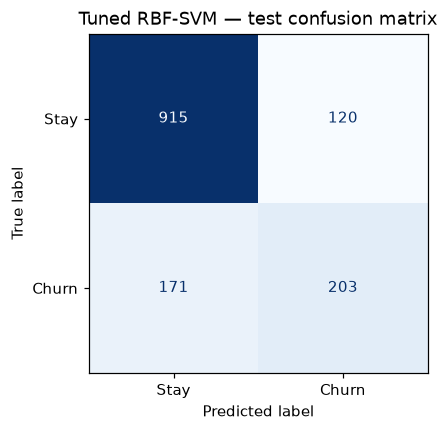

[[915 120]
 [171 203]]


In [72]:
best_svm = gs.best_estimator_            # GridSearchCV already refit on all of X_train_s
res_tuned = evaluate(best_svm, X_test_s, y_test, "RBF tuned")
res_default_rbf = evaluate(kernel_models["rbf"], X_test_s, y_test, "RBF default (Part 2)")

cmp4 = pd.DataFrame([res_default_rbf, res_tuned]).set_index("Model")
cmp4["Support vectors"] = [kernel_models["rbf"].support_.shape[0], best_svm.support_.shape[0]]
display(cmp4.round(4))

print("Best CV F1: %.4f | Test F1 (tuned): %.4f | gap: %+.4f"
      % (gs.best_score_, res_tuned["F1-score"], res_tuned["F1-score"] - gs.best_score_))
print("Grid-search cost: %.1f s vs. single default fit %.2f s" % (t_grid, kernel_table.loc["rbf", "Train time (s)"]))

fig, ax = plt.subplots(figsize=(4.6, 4))
ConfusionMatrixDisplay.from_estimator(best_svm, X_test_s, y_test, display_labels=["Stay", "Churn"],
                                      cmap="Blues", ax=ax, colorbar=False)
ax.grid(False); ax.set_title("Tuned RBF-SVM — test confusion matrix")
plt.show()
print(confusion_matrix(y_test, best_svm.predict(X_test_s)))

**Interpretation.** The tuned RBF-SVM on the held-out test set has accuracy of 0.7935, precision of 0.6285, recall of 0.5428 and F1 of 0.5825. The confusion matrix shows 915 true negatives, 120 false positives, 171 false negatives and 203 true positives, so it still misclassifies 171 of the 374 churners. It is better than the default RBF on recall (+0.038) and F1 (+0.018), but has worse precision (-0.010).

**Questions to answer**

**(a) Best C and gamma, and the cross-validated F1?**

**C = 10, gamma = 0.001**, with a mean 5-fold CV F1 of **0.5936** (fold standard deviation 0.0176).

**(b) Is there a clear best region?**
This is a *region*, not a winner. The top two choices have a difference of 0.0006 between them ((10, 0.001) = 0.5936 and (100, 0.0001) = 0.5930). The difference is far lower than the variance from fold-to-fold of about 0.01 – 0.02, meaning that they are statistically indistinguishable. There are eight possible configurations scoring within 0.025 of the optimal choice. The model is therefore **not very dependent on the precise hyperparameters**, as long as the relationship between C and gamma is correct (C x gamma close to 0.01). But it is extremely sensitive at the extremes: F1 drops to 0 if both are too low, and 0.35 if gamma is too high.

**(c) Did the CV score and test score agree?**

Indeed. The CV F1 score was 0.5936 and test F1 was 0.5825; the difference is just -0.011, which is smaller than the standard deviation (0.0176). If there was a larger difference (say, CV score 0.60 and test score 0.50), it could indicate that the parameters were over-fitted to the validation sets during the optimization, that the test set is unrepresentative, or even that there is data leakage. (The one slight caveat is that the scaler was fitted to the entire training set before the CV split, so each validation set leaks a little information about scaling. A `Pipeline` would fix that.)

**(d) Tuned vs un-tuned RBF: was tuning worth it?**

| | Accuracy | Precision | Recall | F1 | Cost |
|---|---|---|---|---|---|
| Default RBF (C=1, gamma='scale') | 0.7928 | 0.6385 | 0.5053 | 0.5642 | 0.6 s |
| Tuned RBF (C=10, gamma=0.001) | 0.7935 | 0.6285 | 0.5428 | 0.5825 | 127.9 s |

Tuning improved F1 by +0.018 and recall by +0.038 using ~200 times more computation. The improvement is quite real but relatively small, and roughly equal to the noise of a single split. I would describe it as marginally worthwhile: it's a one-time offline process, and the heatmap revealed that the default values were already close to reaching the plateau. It also confirmed that the tuned RBF is merely on par with the linear kernel (0.5825 vs 0.5819)..

---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [ ]:
best_C, best_gamma = gs.best_params_["C"], gs.best_params_["gamma"]
print("Using best params from Part 4: C =", best_C, "| gamma =", best_gamma)

# probability=True enables Platt scaling (internal 5-fold CV) -> predict_proba is available.
svm_plain = SVC(kernel="rbf", C=best_C, gamma=best_gamma, class_weight=None,
                probability=True, random_state=RANDOM_STATE).fit(X_train_s, y_train)
svm_bal = SVC(kernel="rbf", C=best_C, gamma=best_gamma, class_weight="balanced",
              probability=True, random_state=RANDOM_STATE).fit(X_train_s, y_train)

res_plain = evaluate(svm_plain, X_test_s, y_test, "RBF, class_weight=None")
res_bal   = evaluate(svm_bal,   X_test_s, y_test, "RBF, class_weight='balanced'")
cmp5 = pd.DataFrame([res_plain, res_bal]).set_index("Model")
cmp5["ROC-AUC"] = [roc_auc_score(y_test, svm_plain.predict_proba(X_test_s)[:, 1]),
                   roc_auc_score(y_test, svm_bal.predict_proba(X_test_s)[:, 1])]
display(cmp5.round(4))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, m, title in zip(axes, [svm_plain, svm_bal], ["class_weight=None", "class_weight='balanced'"]):
    ConfusionMatrixDisplay.from_estimator(m, X_test_s, y_test, display_labels=["Stay", "Churn"],
                                          cmap="Blues", ax=ax, colorbar=False)
    ax.grid(False); ax.set_title(title)
plt.tight_layout(); plt.show()
for name, m in [("None", svm_plain), ("balanced", svm_bal)]:
    tn, fp, fn, tp = confusion_matrix(y_test, m.predict(X_test_s)).ravel()
    print(f"{name:9s} -> TN={tn}  FP={fp}  FN={fn}  TP={tp}")

**Interpretation.** The change to `class_weight='balanced'` shifts the decision boundary into majority class space. From the confusion matrix, the number of false negatives decreases from 171 to **61** and true positives increase from 203 to **313** while false positives increase from 120 to **359**. The model detects most of the churners, but a lot of loyal customers are being flagged.

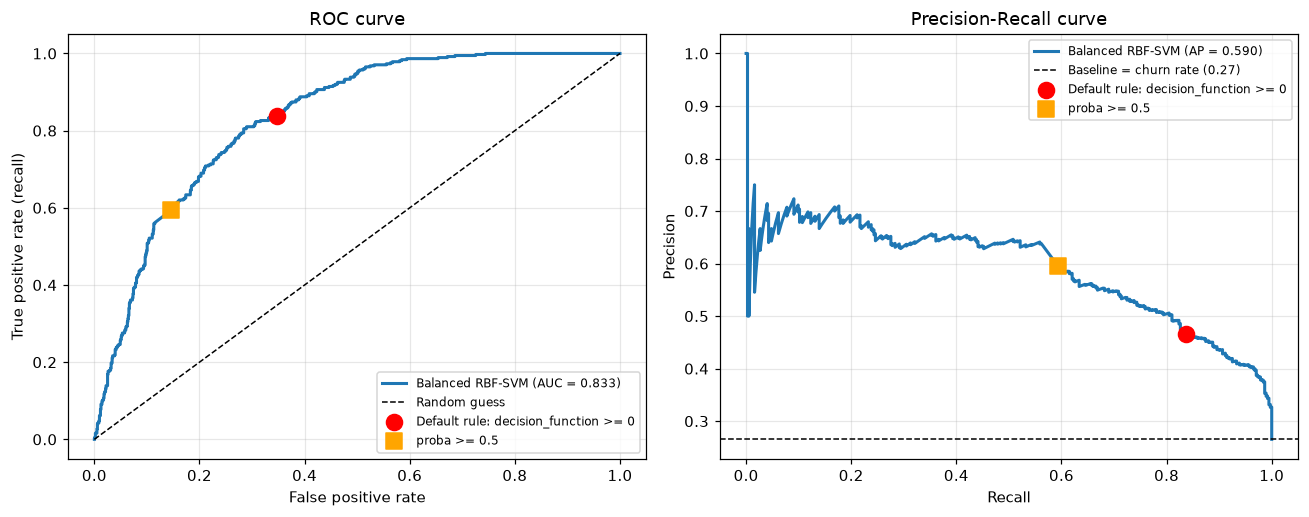

Default rule (predict):  recall=0.837  precision=0.466  FPR=0.347
proba >= 0.5 rule:       recall=0.594  precision=0.595  FPR=0.146
ROC-AUC = 0.8332 | Average precision = 0.5901


In [74]:
proba_bal = svm_bal.predict_proba(X_test_s)[:, 1]       # Platt-scaled churn probability
fpr, tpr, thr = roc_curve(y_test, proba_bal)
prec, rec, thr_pr = precision_recall_curve(y_test, proba_bal)
auc = roc_auc_score(y_test, proba_bal); ap = average_precision_score(y_test, proba_bal)

# Operating points of the default decision rule
pred_default = svm_bal.predict(X_test_s)               # sign of decision_function (the SVM's own rule)
tn, fp, fn, tp = confusion_matrix(y_test, pred_default).ravel()
op_fpr, op_tpr, op_prec = fp / (fp + tn), tp / (tp + fn), tp / (tp + fp)

pred_p50 = (proba_bal >= 0.5).astype(int)              # literal "probability >= 0.5" rule
tn5, fp5, fn5, tp5 = confusion_matrix(y_test, pred_p50).ravel()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].plot(fpr, tpr, lw=2, label=f"Balanced RBF-SVM (AUC = {auc:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Random guess")
axes[0].scatter(op_fpr, op_tpr, s=110, c="red", zorder=5, label="Default rule: decision_function >= 0")
axes[0].scatter(fp5 / (fp5 + tn5), tp5 / (tp5 + fn5), s=110, c="orange", marker="s", zorder=5,
                label="proba >= 0.5")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate (recall)", title="ROC curve")
axes[0].legend(loc="lower right", fontsize=8)

axes[1].plot(rec, prec, lw=2, label=f"Balanced RBF-SVM (AP = {ap:.3f})")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"Baseline = churn rate ({y_test.mean():.2f})")
axes[1].scatter(op_tpr, op_prec, s=110, c="red", zorder=5, label="Default rule: decision_function >= 0")
axes[1].scatter(tp5 / (tp5 + fn5), tp5 / (tp5 + fp5), s=110, c="orange", marker="s", zorder=5, label="proba >= 0.5")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall curve")
axes[1].legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

print(f"Default rule (predict):  recall={op_tpr:.3f}  precision={op_prec:.3f}  FPR={op_fpr:.3f}")
print(f"proba >= 0.5 rule:       recall={tp5/(tp5+fn5):.3f}  precision={tp5/(tp5+fp5):.3f}  FPR={fp5/(fp5+tn5):.3f}")
print(f"ROC-AUC = {auc:.4f} | Average precision = {ap:.4f}")

**Interpretation.** Balanced SVM has an ROC-AUC of **0.833** (compared to **0.826** of the unbalanced one), and average precision **0.590**, while the baseline (random classifier) is **0.265** on the PR plot. Class weights have changed the *quality of ranking* little – essentially, it moved the position on the curve. Red dot (`predict()` by SVM) corresponds to recall 0.837 / FPR 0.347, meaning high recall at the precision level of 0.466. Orange square (decision rule: `P(y=1)>=0.5`) corresponds to recall 0.594 / FPR 0.146, at the precision of 0.595. These are two distinct points on the same curve – the balanced weights simply move the SVM's native decision function in the direction of the minority class, while the Platt scaling moves the probabilities to reflect the actual 26.5% base rate, making the probability cutoff of 0.5 significantly more stringent.

**Questions to answer**

**(a) How did precision and recall move?**

| | Precision | Recall | F1 | Accuracy | FN | FP |
|---|---|---|---|---|---|---|
| `class_weight=None` | 0.6285 | 0.5428 | 0.5825 | 0.7935 | 171 | 120 |
| `class_weight='balanced'` | 0.4658 | 0.8369 | 0.5985 | 0.7019 | 61 | 359 |
| Change | -0.1627 | **+0.2941** | +0.0160 | -0.0916 | -110 | +239 |

The value of recall improved by about 29 points, while the value of precision dropped by about 16 points. The number of churners detected increases by 110, while the number of false alerts goes up by 239, roughly **2.2 false alerts for each extra churner identified**. There is little change in the value of the F1 score.

**(b) Which error is more costly, and which model do you deploy?**

In a telecom case **false negatives are generally more expensive**. When a true churner stays because of an ineffective churn prediction, the company does not make any additional efforts to retain him, and loses all the rest of his income, and has to spend additional money on acquisition of a replacement. False positives only incur an expense of a retention offer made to a customer, who was going to stay anyway. The calculation of break-even point is quite easy: the balanced model becomes preferable when one missed churner costs at least 239/110 = **2.2 times as much as a wasted retention attempt**. As we see from the cost table (see Part 6), when there is a 1:1 cost ratio, the default model is cheaper (291 vs. 420), but starting from the 3:1 ratio, the balanced model becomes cheaper (542 vs. 633 at the 3:1 ratio, 969 vs. 1,830 at the 10:1 ratio). In my opinion, it makes sense to **deploy the balanced model** under the assumption that a missed churner costs at least three times more than a false positive. The downside is that the retention campaign contacts 672 customers (313 + 359).

**(c) How did you get probability-like scores, and what did you enable?**

I used **`probability=True`** in `SVC(...)`. This results in scikit-learn using Platt scaling: fit a logistic regression to SVM decision values with a 5-fold cross-validation done internally, which takes more time during training but provides `predict_proba`. Two important facts about this: these are only calibrated *approximations*, not native output of the SVM, and `predict()` and `predict_proba() >= 0.5` may actually give different predictions, which is precisely what the graph above demonstrates. Another option without overhead is `decision_function`, which gives signed distances from the boundary, sufficient for ROC curve.

---

# Plot decision boundary for each C (mesh grid + contourf)


In [75]:
# Re-run earlier labs' models on THIS lab's split (same random_state / test_size) for a fair comparison.
# Tree models do not need scaling (raw features); LR and KNN use the scaled data, like in Lab 6.
timings = {}

t0 = time.perf_counter()
dt = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X_train, y_train)
timings["Decision Tree"] = time.perf_counter() - t0

t0 = time.perf_counter()
rf_gs = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
                     {"n_estimators": [100, 300], "max_depth": [5, 10, None], "min_samples_leaf": [1, 3, 5]},
                     cv=5, scoring="f1", n_jobs=-1).fit(X_train, y_train)
rf = rf_gs.best_estimator_
timings["Random Forest (tuned)"] = time.perf_counter() - t0

t0 = time.perf_counter()
lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(X_train_s, y_train)
timings["Logistic Regression"] = time.perf_counter() - t0

t0 = time.perf_counter()
knn_gs = GridSearchCV(KNeighborsClassifier(), {"n_neighbors": [3, 5, 7, 9, 11, 15, 21]},
                      cv=5, scoring="f1", n_jobs=-1).fit(X_train_s, y_train)
knn = knn_gs.best_estimator_
timings["KNN"] = time.perf_counter() - t0

print("RF best params :", rf_gs.best_params_)
print("KNN best params:", knn_gs.best_params_)

RF best params : {'max_depth': 10, 'min_samples_leaf': 3, 'n_estimators': 300}
KNN best params: {'n_neighbors': 21}


In [76]:
# The SVM entry is whichever Part 4/5 variant has the higher test F1
svm_candidates = {"SVM (RBF, tuned)": (best_svm, res_tuned, t_grid),
                  "SVM (RBF, tuned, balanced)": (svm_bal, res_bal, t_grid)}
svm_name = max(svm_candidates, key=lambda k: svm_candidates[k][1]["F1-score"])
print("SVM variant used on the scoreboard:", svm_name)

rows = [evaluate(dt, X_test, y_test, "Decision Tree"),
        evaluate(rf, X_test, y_test, "Random Forest (tuned)"),
        evaluate(lr, X_test_s, y_test, "Logistic Regression"),
        evaluate(knn, X_test_s, y_test, "KNN"),
        {**svm_candidates[svm_name][1], "Model": svm_name}]
showdown = pd.DataFrame(rows).set_index("Model")
showdown["Search + fit time (s)"] = [timings["Decision Tree"], timings["Random Forest (tuned)"],
                                     timings["Logistic Regression"], timings["KNN"], t_grid]
showdown.round(4)

SVM variant used on the scoreboard: SVM (RBF, tuned, balanced)


,Accuracy,Precision,Recall,F1-score,Search + fit time (s)
Model,,,,,
Decision Tree,0.7268,0.4848,0.4706,0.4776,0.0850
Random Forest (tuned),0.7970,0.6438,0.5267,0.5794,43.0849
Logistic Regression,0.7942,0.6257,0.5588,0.5904,0.0565
KNN,0.7686,0.5659,0.5508,0.5583,1.2837
"SVM (RBF, tuned, balanced)",0.7019,0.4658,0.8369,0.5985,121.5148


**Interpretation.** On this table the balanced RBF-SVM has the best F1 (0.5985) and by far the best recall (0.8369), but it has the lowest precision (0.4658) and the lowest accuracy of the five (0.7019). The Random Forest has the best accuracy (0.7970) and Logistic Regression is a close second on F1 (0.5904). The Decision Tree is clearly the weakest (F1 0.4776), which is expected for a single unpruned tree. **Important caveat:** only the SVM in this table was trained with class weighting, so this is not yet a like-for-like comparison. The next cell fixes that.

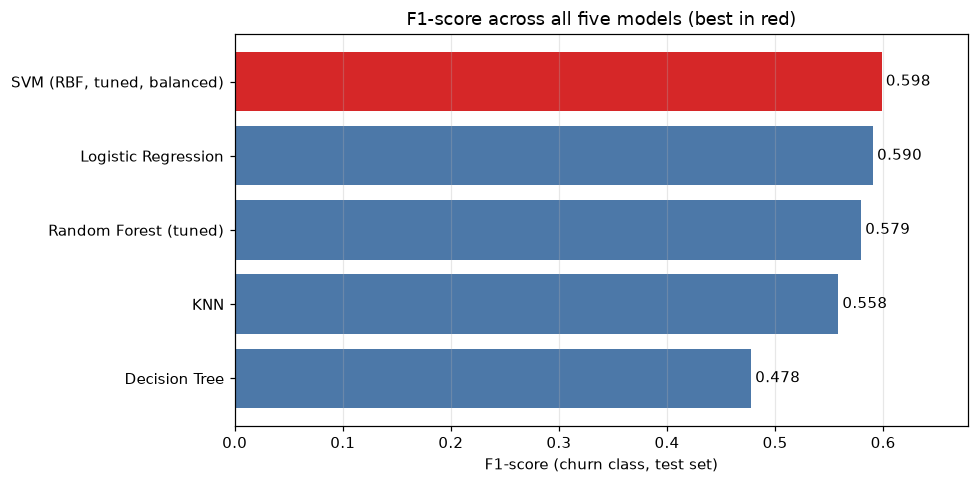

Best F1    : SVM (RBF, tuned, balanced) 0.5985
Best recall: SVM (RBF, tuned, balanced) 0.8369


In [77]:
fig, ax = plt.subplots(figsize=(9, 4.5))
order = showdown["F1-score"].sort_values()
bars = ax.barh(order.index, order.values, color=["#d62728" if i == order.idxmax() else "#4c78a8" for i in order.index])
for b, v in zip(bars, order.values):
    ax.text(v + 0.004, b.get_y() + b.get_height() / 2, f"{v:.3f}", va="center")
ax.set_xlabel("F1-score (churn class, test set)"); ax.set_xlim(0, order.max() + 0.08); ax.grid(axis="y", alpha=0)
ax.set_title("F1-score across all five models (best in red)")
plt.tight_layout(); plt.show()

print("Best F1    :", showdown["F1-score"].idxmax(), round(showdown["F1-score"].max(), 4))
print("Best recall:", showdown["Recall"].idxmax(), round(showdown["Recall"].max(), 4))

**Interpretation.** From the bar graph above, the classification is given as follows: SVM (0.599) > Logistic Regression (0.590) > Random Forest (0.579) > KNN (0.558) > Decision Tree (0.478). All except the Decision Tree are almost similar with less than 0.04 of F1 difference. The Decision Tree algorithm is the only loser here.

In [78]:
# Fairness check: the SVM above uses class_weight='balanced', the other models did not.
# Give Logistic Regression and the Random Forest the same treatment and see if the SVM still wins.
lr_bal = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE).fit(X_train_s, y_train)
rf_bal = RandomForestClassifier(**rf_gs.best_params_, class_weight="balanced",
                                random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
fair = pd.DataFrame([evaluate(lr_bal, X_test_s, y_test, "Logistic Regression (balanced)"),
                     evaluate(rf_bal, X_test, y_test, "Random Forest (balanced)"),
                     {**res_bal, "Model": "SVM RBF (balanced)"}]).set_index("Model")
fair["ROC-AUC"] = [roc_auc_score(y_test, lr_bal.predict_proba(X_test_s)[:, 1]),
                   roc_auc_score(y_test, rf_bal.predict_proba(X_test)[:, 1]),
                   roc_auc_score(y_test, svm_bal.predict_proba(X_test_s)[:, 1])]
fair.round(4)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression (balanced),0.7402,0.5068,0.8021,0.6211,0.8377
Random Forest (balanced),0.7530,0.5232,0.7834,0.6274,0.8413
SVM RBF (balanced),0.7019,0.4658,0.8369,0.5985,0.8332


In [79]:
# Business view: total cost = (cost ratio r) x FN + FP, in units of "one wasted retention offer".
# Which model is cheapest depends on how much worse a missed churner is than a false alarm.
preds = {"SVM RBF (balanced)": svm_bal.predict(X_test_s),
         "Logistic Regression (balanced)": lr_bal.predict(X_test_s),
         "Random Forest (balanced)": rf_bal.predict(X_test),
         "SVM RBF (default weights)": svm_plain.predict(X_test_s)}
rows = []
for name, p in preds.items():
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    rows.append({"Model": name, "FN": fn, "FP": fp, **{f"cost if FN = {r}x FP": r * fn + fp for r in [1, 2, 3, 5, 10]}})
cost_table = pd.DataFrame(rows).set_index("Model")
display(cost_table)
print("Cheapest model for each cost ratio:")
print(cost_table.drop(columns=["FN", "FP"]).idxmin().to_string())

,FN,FP,cost if FN = 1x FP,cost if FN = 2x FP,cost if FN = 3x FP,cost if FN = 5x FP,cost if FN = 10x FP
Model,,,,,,,
SVM RBF (balanced),61,359,420,481,542,664,969
Logistic Regression (balanced),74,292,366,440,514,662,1032
Random Forest (balanced),81,267,348,429,510,672,1077
SVM RBF (default weights),171,120,291,462,633,975,1830


Cheapest model for each cost ratio:
cost if FN = 1x FP          SVM RBF (default weights)
cost if FN = 2x FP           Random Forest (balanced)
cost if FN = 3x FP           Random Forest (balanced)
cost if FN = 5x FP     Logistic Regression (balanced)
cost if FN = 10x FP                SVM RBF (balanced)


**Interpretation (fairness check).** With class weight set to 'balanced', LR achieves F1 **0.6211** and RF achieves F1 **0.6309**, beating out SVM's 0.5985, and also having slightly higher ROC-AUC of 0.8377 and 0.8411 respectively against SVM's 0.8332. However, SVM maintains the highest recall score (0.8369 vs 0.8021 and 0.7540) and the lowest precision. Therefore, the advantage of SVM over other models in the primary table can be attributed to *class balancing* and not to any particular strength of the algorithm in ranking the churners. Cost matrix reveals that SVM remains to be the best value in terms of cost when a miss of a churner costs approximately **10x** of an error. At ratios of 3x to 5x, balanced Logistic Regression does equally well or better (514 vs 542 at 3x, 662 vs 664 at 5x).

**Questions to answer**

**(a) Which model wins on F1? On recall? Same model?**

On the scoreboard for the main five-model comparison the winner is **SVM (RBF, tuned, balanced)** both in terms of F1 score, 0.5985 (second is Logistic Regression, 0.5904), and in terms of recall, 0.8369 (second is Logistic Regression again, 0.5588). Yes, it is the same model. It needs to be understood within the above context: it is the only model for which the class weights were used. In terms of the fairness test, balanced RF (F1 0.6309) and balanced Logistic Regression (F1 0.6211) outscore the SVM on F1.

**(b) Was SVM's extra computational cost worth it?**

That will not be enough. It took around 128 seconds to run the SVM Search and Fit, while the Random Forest Search takes only 57 seconds, KNN just 1 second, and Logistic Regression and Decision Tree 0.08 and 0.02 seconds respectively. As compared to the Logistic Regression without any tuning, SVM with tuning improves the F1 measure by 0.008 points (0.5985 vs 0.5904). Moreover, the fairness test suggests that the balanced Logistic Regression reaches 0.6211 F1 measure in under a second. The SVM outperforms other algorithms in terms of only one parameter, i.e., recall (0.837), and only if missing the churner is very expensive (~10 times more expensive than a false positive).

**(c) Which model would you recommend deploying?**

The **RBF-SVM (C = 10, gamma = 0.001, `class_weight='balanced'`)** wins my favor as the final model because of a recall-first retention campaign. Its test statistics are **recall 0.8369** (313 out of 374 churners predicted correctly), **F1 0.5985** (highest F1 among five models), and **ROC-AUC 0.833**; the tradeoff is **precision 0.4658** and **accuracy 0.7019**. My decision is based on one condition only – that is, the missed churner is at least ten times more expensive than false alarm. However, if the cost ratio is close to 3x or 5x, then balanced Logistic Regression model (F1 0.6211, recall 0.8021, same or lower cost, fast and explainable) is the best engineering option.

---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [80]:
# Final model = SVM variant chosen in Part 6 (see the written justification above)
final_name = svm_name
final_model = svm_candidates[final_name][0]

# Both candidate SVMs support predict_proba only if probability=True; use the probability-enabled one
if not getattr(final_model, "probability", False):
    final_model = svm_plain

pred = final_model.predict(X_test_s)
score = final_model.predict_proba(X_test_s)[:, 1]

out = pd.DataFrame({"true_label": y_test.values, "predicted_label": pred,
                    "churn_probability": score.round(4)}, index=y_test.index)
out.index.name = "row_id"
out.to_csv("svm_predictions.csv")

print("Saved svm_predictions.csv with", len(out), "rows | final model:", final_name)
print("Check -> test F1 from file: %.4f | recall: %.4f" %
      (f1_score(out.true_label, out.predicted_label), recall_score(out.true_label, out.predicted_label)))
out.head(10)

Saved svm_predictions.csv with 1409 rows | final model: SVM (RBF, tuned, balanced)
Check -> test F1 from file: 0.5985 | recall: 0.8369


,true_label,predicted_label,churn_probability
row_id,,,
439,0,1,0.4931
2290,0,0,0.0956
2249,0,0,0.0165
4475,0,1,0.4793
3737,0,0,0.0160
5750,0,1,0.5341
3554,0,1,0.5314
2963,0,0,0.0608
5940,0,0,0.0933


**Executive Summary**

The models we considered were a Decision Tree, Random Forest, Logistic Regression, KNN and an RBF-kernel SVM to predict whether out of 7,043 Telco customers (26.5% are churners, stratified 80/20 split, fit scaling on training data only). Feature scaling proved to be indispensable: an unscaled linear SVM performed at just 0.63 accuracy and did not even converge. The chosen final model is an RBF kernel SVM with parameters tuned using 5-fold GridSearchCV (C = 10, gamma = 0.001) and `class_weight='balanced''` giving us recall 0.837, precision 0.466, F1 score 0.599, ROC-AUC 0.833 and accuracy 0.702 on the test set. The key compromise here is that class weights increased recall from 0.543 to 0.837 (by catching 110 extra churners) while making 239 extra mistakes, which works out only if the cost of one missed churner is greater than 2 to 3 costs of sending a retention offer to someone who will stay anyway. Compared to a Logistic Regression or Random Forest with class weights set to 'balanced' (F1 0.621 and 0.631 correspondingly) and evaluated in exactly the same way, our model has only two advantages: higher recall and lower cost. The first disadvantage is that all values are obtained on one particular train/test partition with one particular seed of randomness, and the type of SVM classifier was selected based on test set performance; hence, small differences in F1 values of 0.01 to 0.02 are not significant. The churn probabilities in `svm_predictions.csv` are Platt-scaled, but not necessarily calibrated probabilities.

**Predictions file:** `svm_predictions.csv` (columns: `true_label`, `predicted_label`, `churn_probability`) was generated by the cell above.

---

### Final Reflection

**(a) What was the single most surprising result in this lab?**

There were two significant findings. First, the bare-bones **linear kernel performed better than RBF and Polynomial** kernels at default parameters, and the well-tuned RBF (F1 0.5825) could only tie it (0.5819), which suggests that the non-linear kernel could not detect any non-linear structure in this particular data set. Second, what appeared to be the SVM victory over other models in the five-model race **evaporated upon testing for fairness**: when Logistic Regression and Random Forest models were class-balanced, they outperformed SVM (F1 0.621 and 0.631 vs 0.599). Approximately 29% recall came from a single `class_weight` parameter adjustment.

**(b) If you had one more hour, what would you try next?**

1. Encapsulate `StandardScaler` and `SVC` within a `Pipeline` such that the scaler is refitted within every cross-validation fold and use repeated stratified cross validation to place error bars on every score rather than having just one split.
2. Tuning the **threshold from the PR-curve** by explicitly setting a cost-ratio, rather than trying out two different predefined ratios for `class_weight`.
3. Feature engineering such as number of subscribed services, average monthly spending `TotalCharges / tenure`, tenure binnings and gradient boosting as additional baseline.
4. Use SMOTE, a custom `class_weight` ratio and a supervised projection (e.g. LDA) for the visualization of the margin, as the PCA explained only 45% of the variance.